# 04 · Simulation

Backtests of the stock-picking rules. **Part 1: the baseline rule grid. Part 2: the models from
notebook 03, traded** with the same simulation, against SPY and the rules.

**The rule:** at each month-end, buy the top 1, 5 or 10 members by their past return (over 1, 3, 6 or
12 months, or 12 months skipping the latest), equal weight, at the next open, and hold for 1, 3, 6 or
12 months. That's 5 × 3 × 4 = **60 rules**, and every one is reported.

**How it's simulated:**
- **Staggered portfolios.** With an X-month hold, 1/X of the money is reinvested each month, so the
  result doesn't depend on the starting month.
- **Costs.** 10 bps (0.1%) are charged on every buy and every sell. A stock kept from one month's
  picks to the next is only traded by the weight difference.
- **Delistings.** A delisted stock is valued at its last price and then held as cash.
- **Benchmarks.** SPY, and an equal-weight basket of every member rebalanced monthly. Both are
  gross: SPY's fee is in its price, and the basket is a yardstick, not a strategy.

The rule fits nothing, so it runs over the **whole period (Feb 2010 to Oct 2026)** with no train/test
split. But picking the best of 60 is itself a choice, so Section 4 chooses the best rule on the
development years (decisions 2010–2022) only and follows it through the **test years (decisions
from January 2023, so returns from February 2023)**, the same untouched window the models are
scored on. Every period here is set by decision date: a month-end decision earns next month's return.

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
> The early years still miss most acquired companies (survivorship bias flatters the rule).

In [1]:
import pandas as pd

from sp500_momentum import backtest as bt
from sp500_momentum import config, nb, plots

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

## 1. The rule columns

Each rule is a 0/1 column on the monthly table (`pred_mom_<look-back>_top<N>`): 1 means "buy this member
at the next open". For example, the five picks of the 6-month rule at the latest month-end:

In [2]:
panel = bt.add_rule_preds(pd.read_parquet(config.MONTHLY_PANEL))
preds = [c for c in panel if c.startswith("pred_mom_")]
last = panel["date"].max()
print(
    f"{len(preds)} rule columns; picks per month-end: "
    f"{panel.groupby('date')[preds].sum().iloc[:-1].mean().round(1).unique().tolist()}"
)
panel.loc[(panel["date"] == last) & (panel["pred_mom_6m_top5"] == 1), ["date", "ticker", "ret_6m"]]

15 rule columns; picks per month-end: [1.0, 5.0, 10.0]


,date,ticker,ret_6m
101041,2026-10-30,CRL,1.1525
101043,2026-10-30,CRWD,1.2473
101059,2026-10-30,DELL,1.0368
101242,2026-10-30,MRNA,3.8263
101282,2026-10-30,PANW,1.0403


## 2. Benchmarks

In [3]:
values = bt.value_matrix(pd.read_parquet(config.MONTHLY_PRICES))
bench = bt.benchmark_returns(panel, values)
rf = bt.risk_free(pd.read_csv(config.FRED_DIR / "FEDFUNDS.csv"))
print(f"Months earned: {len(bench)} ({bench.index.min()} to {bench.index.max()})")
cols = ["cagr", "volatility", "sharpe", "max_drawdown", "beats_spy_months"]
bt.benchmark_table(bench, rf)[cols]

Months earned: 201 (2010-02 to 2026-10)


,cagr,volatility,sharpe,max_drawdown,beats_spy_months
spy,0.1434,0.1481,0.8804,-0.2331,NaN
equal_weight,0.1381,0.1610,0.7941,-0.3021,0.5075


The equal-weight basket earns about the same as SPY, with more volatility and a deeper fall. Sharpe
ratios here subtract the Fed Funds rate as the risk-free return.

## 3. The full grid (about a minute to run)

In [4]:
rets, costs = bt.run_grid(panel, values, config.HOLD_MONTHS)
grid = bt.grid_table(rets, bench, rf, costs)
grid.to_csv(config.REPORTS_DIR / "baseline_grid_2010_2026.csv")  # all 60 rules + benchmarks
print(f"{rets.shape[1]} rules simulated; the full table is in reports/baseline_grid_2010_2026.csv")
show = [
    "lookback",
    "top_n",
    "hold",
    "cagr",
    "volatility",
    "sharpe",
    "max_drawdown",
    "t_vs_spy",
    "cost_per_year",
]
grid[show].head(10)

60 rules simulated; the full table is in reports/baseline_grid_2010_2026.csv


,lookback,top_n,hold,cagr,volatility,sharpe,max_drawdown,t_vs_spy,cost_per_year
cell,,,,,,,,,
pred_mom_6m_top5_h6,ret_6m,5,6,0.2880,0.2890,0.9705,-0.2733,2.8329,0.0037
pred_mom_6m_top5_h12,ret_6m,5,12,0.2508,0.2561,0.9476,-0.2717,2.6264,0.0020
pred_mom_6m_top5_h3,ret_6m,5,3,0.2820,0.2918,0.9463,-0.2375,2.6262,0.0061
pred_mom_3m_top10_h12,ret_3m,10,12,0.2048,0.2169,0.9030,-0.2776,2.1023,0.0019
pred_mom_1m_top5_h12,ret_1m,5,12,0.2036,0.2215,0.8836,-0.3553,2.1870,0.0020
pred_mom_3m_top10_h6,ret_3m,10,6,0.2103,0.2300,0.8833,-0.3030,1.9903,0.0038
pred_mom_6m_top10_h12,ret_6m,10,12,0.2130,0.2345,0.8811,-0.2540,2.1084,0.0019
spy,NaN,<NA>,<NA>,0.1434,0.1481,0.8804,-0.2331,NaN,NaN
pred_mom_1m_top10_h12,ret_1m,10,12,0.1869,0.2041,0.8722,-0.3294,1.9572,0.0020


The ten best rules by Sharpe ratio. `t_vs_spy` is the t-statistic of the average monthly return
over SPY's. About 2 would be convincing for one rule chosen in advance, but the grid tries 60, so a few
cells clear 2 by chance alone.

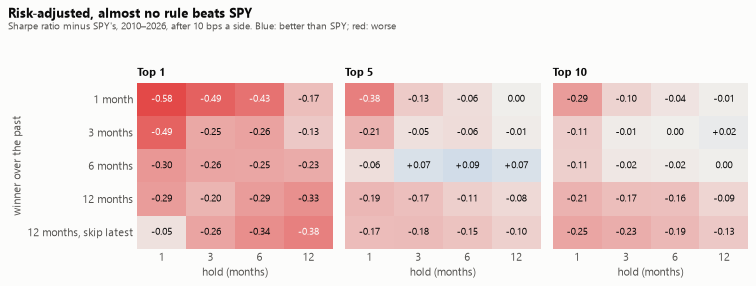

In [5]:
fig = plots.grid_heatmap(
    grid,
    "Risk-adjusted, almost no rule beats SPY",
    "Sharpe ratio minus SPY's, 2010–2026, after 10 bps a side. Blue: better than SPY; red: worse",
)
plots.save(fig, "baseline_grid_sharpe")

How many of the 60 rules beat SPY, by each dimension of the grid:

In [6]:
pd.concat({by: bt.grid_summary(grid, by) for by in ["top_n", "lookback", "hold"]})

cells  higher_return  higher_sharpe  median_cagr  median_sharpe  median_max_drawdown
top_n    1             20             15              0       0.1987         0.6046              -0.5420
         5             20             19              4       0.2020         0.7905              -0.3374
         10            20             19              3       0.1805         0.7765              -0.3137
lookback ret_12_1m     12             11              0       0.1852         0.6972              -0.3230
         ret_12m       12             12              0       0.1946         0.6997              -0.4078
         ret_1m        12              7              1       0.1708         0.7327              -0.4134
         ret_3m        12             11              2       0.2076         0.7913              -0.3324
         ret_6m        12             12              4       0.2282         0.8403              -0.3005
hold     1             15             11              0       0.1813         0.6685              -0.4049
         3             15             14              1       0.2004         0.7120              -0.3908
         6             15             14              2       0.1988         0.7289              -0.3576
         12            15             14              4       0.1987         0.7928              -0.3294

In [7]:
cells = grid.dropna(subset=["top_n"])
spy = grid.loc["spy"]
print(
    f"Higher return than SPY: {(cells['cagr'] > spy['cagr']).sum()} of {len(cells)}; "
    f"higher Sharpe: {(cells['sharpe'] > spy['sharpe']).sum()}; "
    f"deeper worst fall: {(cells['max_drawdown'] < spy['max_drawdown']).sum()}; "
    f"t > 2: {(cells['t_vs_spy'] > 2).sum()}; t > 3: {(cells['t_vs_spy'] > 3).sum()}"
)
cells.groupby("hold")["cost_per_year"].mean().rename("average cost per year").to_frame()

Higher return than SPY: 53 of 60; higher Sharpe: 7; deeper worst fall: 60; t > 2: 9; t > 3: 0


,average cost per year
hold,
1,0.0141
3,0.0063
6,0.0036
12,0.0020


## 4. Is the best rule luck? Chosen on 2010–2022, followed through the test years

The rule with the best Sharpe ratio on decisions **2010–2022** is fixed, then scored on decisions from
**January 2023** (returns from February 2023: the test window, never used to choose), next to SPY and
the equal-weight basket.

In [8]:
best, check, rank = bt.selection_check(rets, bench, rf, costs, config.RULE_CHECK_FROM)
print(
    f"Chosen: {plots.cell_label(**bt.parse_cell(best))} ({best}); "
    f"its Sharpe rank among the 60 in the test years: {rank}"
)
check

Chosen: Top 5 by 6-month return, held 6 months (pred_mom_6m_top5_h6); its Sharpe rank among the 60 in the test years: 3


cagr  volatility  sharpe  max_drawdown  beats_spy_months  months
       cell                                                                                  
before pred_mom_6m_top5_h6 0.2084      0.2297  0.9173       -0.2590            0.6090     156
       spy                 0.1283      0.1558  0.8142       -0.2331               NaN     156
       equal_weight        0.1414      0.1698  0.8299       -0.3021            0.5256     156
after  pred_mom_6m_top5_h6 0.6068      0.4309  1.2123       -0.2733            0.6222      45
       spy                 0.1974      0.1183  1.2059       -0.0780               NaN      45
       equal_weight        0.1270      0.1273  0.6481       -0.1133            0.4444      45

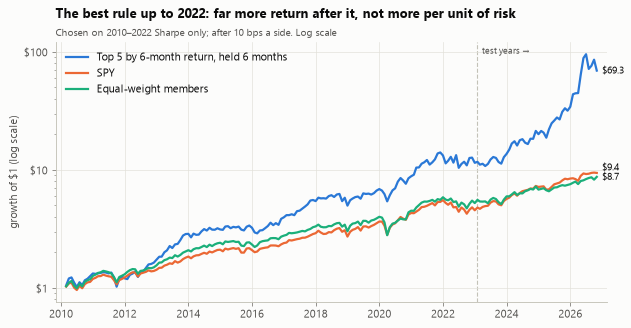

In [9]:
fig = plots.rule_growth_chart(
    rets[best],
    bench,
    plots.cell_label(**bt.parse_cell(best)),
    "The best rule up to 2022: far more return after it, not more per unit of risk",
    "Chosen on 2010–2022 Sharpe only; after 10 bps a side. Log scale",
    mark=config.RULE_CHECK_FROM,
    mark_label="test years →",
)
plots.save(fig, "baseline_best_rule")

Which stocks drove the rule in the test years: the members it picked most often.

In [10]:
best_pred = best.rsplit("_h", 1)[0]
late = panel[(panel[best_pred] == 1) & (panel["date"] >= config.RULE_CHECK_FROM)]
late["ticker"].value_counts().head(8).rename("month-ends picked").to_frame()

,month-ends picked
ticker,
NVDA,14
WDC,13
PLTR,13
STX,10
GEV,9
SNDK,9
MU,8
META,7


## 5. What Part 1 means

- **On raw return the rule looks good; on risk it doesn't.** 53 of the 60 rules earn more than SPY, but
  only 7 have a better Sharpe ratio, and all 60 have a deeper worst fall. Buying winners mostly buys
  more risk.
- **Six-month winners, held longer, are the best corner.** The 6-month look-back has the best median
  return, Sharpe ratio and worst fall. Last month's return has the lowest median return and the deepest
  falls (the short-term reversal seen in the feature analysis), and costs fall from about 1.4% a year
  with a 1-month hold to 0.2% with a 12-month hold.
- **A single stock is far too risky.** Top-1 rules have a median worst fall of −54%, against SPY's −23%.
- **The best rule on 2010–2022 earned far more in the test years, and matched SPY per unit of risk.**
  It's the top 5 by 6-month return, held 6 months (Sharpe 0.92 vs SPY's 0.81 on decisions 2010–2022).
  On the test years it made 61% a year against SPY's 20%, ranking 3rd of 60. But it did so with 43%
  volatility against SPY's 12%, and a worst fall of −27% against −8%. Its Sharpe was a tie: 1.21 vs
  1.21. The gain came from a handful of AI, data-storage and memory-chip stocks: a bet on a market theme,
  not a steady edge.
- **The test window is set by decision date** (returns from February 2023). Counting returns from
  January 2023 instead would have scored this rule on one month of its selection years. The definition
  was fixed before these numbers were seen. It moved SPY's test Sharpe from 1.29 to 1.21, because
  January 2023 was a strong month for SPY.
- **The bar for the models:** beat SPY on a risk-adjusted basis at top 10. The best top-10 rule over
  2010–2026 has a Sharpe ratio of 0.90 vs SPY's 0.88, close to a tie.

All of these are re-checked after the Alpha Vantage download finishes.


# Part 2 · The models, traded

Each model's top picks, bought at the next open and **held one month** (the models predict next
month), with 10 bps a side. Four versions of every strategy, all fixed before any result was seen:

| Version | How the money is split | When a stock is sold |
| --- | --- | --- |
| Equal weight (main) | Evenly | When it leaves the top N |
| Equal weight + buffer | Evenly | Only when it falls out of the top 2N; the gap goes to the best new name |
| Inverse vol | More to calmer stocks: ∝ 1 / 3-month volatility at the month-end | When it leaves the top N |
| Inverse vol + buffer | ∝ 1 / volatility | Only when it falls out of the top 2N |

A stock that stays in the basket is never sold and rebought: only the difference to its target
weight is traded and charged. Two periods are shown: **2020–2022**, where the headline model was
chosen, and the **test years**. 2014–2019 is left out: the models' scores for those years come from
the same folds their settings were chosen on, so they would flatter them. Dollar amounts start from
$10,000 at the start of each period.

In [11]:
from sp500_momentum.modeling.models import SPECS

scores = pd.read_parquet(config.MODEL_SCORES)
comparison = pd.read_csv(config.REPORTS_DIR / "model_comparison.csv")
headline = comparison.loc[comparison["headline"], "model"].iloc[0]
models = [c for c in scores.columns if c not in ("date", "ticker", "price_ticker", "period")]
signals = {m: m for m in models} | {"mom_1m": "ret_1m", "mom_6m": "ret_6m"}
features = pd.read_parquet(
    config.FEATURES_TABLE, columns=["date", "price_ticker", config.INVERSE_VOL_FEATURE]
)
vol = bt.volatility_lookup(features, config.INVERSE_VOL_FEATURE)

scored = bt.merge_scores(panel, scores, models)
strat_rets, strat_costs = bt.run_strategies(scored, values, signals, vol)
strat_rets["chosen_rule"], strat_costs["chosen_rule"] = rets[best], costs[best]
# decision windows [start, end): the validation block ends where the test block starts
periods = {
    "2020–2022": (config.SPLIT["validation"][0], config.RULE_CHECK_FROM),
    "test years": (config.RULE_CHECK_FROM, None),
}
tables = {
    p: bt.strategy_table(strat_rets, strat_costs, bench, rf, a, b) for p, (a, b) in periods.items()
}
pd.concat(tables, names=["period"]).to_csv(config.REPORTS_DIR / "strategies_2020_2026.csv")
for p, (a, b) in periods.items():
    m = bt.earned_months(strat_rets.index, a, b)
    print(f"{p}: returns earned {m.min()} to {m.max()} ({len(m)} months)")
print(
    f"{strat_rets.shape[1] - 1} model and rule strategies, plus the chosen grid rule; "
    f"headline: {SPECS[headline].label}. Every cell is in reports/strategies_2020_2026.csv"
)

2020–2022: returns earned 2020-02 to 2023-01 (36 months)
test years: returns earned 2023-02 to 2026-10 (45 months)
120 model and rule strategies, plus the chosen grid rule; headline: XGBoost, by how much. Every cell is in reports/strategies_2020_2026.csv


## 6. The headline model against SPY and the rules (2020–2022)

The headline at top 10 in its four versions, next to SPY, the all-members basket, the rule chosen on
2010–2022 in Part 1, and the 1-month-hold rules at the same top 10. `end_value` is what $10,000
became; `traded_per_year` is buys plus sells as a share of the portfolio (2.0 = the whole portfolio
replaced once a year).

In [12]:
model_labels = {m: SPECS[m].label for m in SPECS} | {"average": "Average of the models"}
chosen_label = plots.cell_label(**bt.parse_cell(best))
main = [f"{headline}_top10_{v}" for v in bt.VERSIONS] + [
    "mom_6m_top10_equal",
    "mom_6m_top10_equal_buffer",
    "mom_1m_top10_equal",
    "mom_1m_top10_equal_buffer",
    "chosen_rule",
    "spy",
    "equal_weight",
]
labels = {n: plots.strategy_label(n, model_labels, chosen_label) for n in main}
kinds = {
    n: "benchmark" if n in bench else "model" if n.startswith(headline) else "rule" for n in main
}
show = [
    "end_value",
    "cagr",
    "volatility",
    "sharpe",
    "max_drawdown",
    "beats_spy_months",
    "traded_per_year",
    "fees_dollars",
]


def main_table(period):
    t = tables[period].loc[main, show].copy()
    t.index = [labels[n] for n in t.index]
    return t.sort_values("sharpe", ascending=False)


main_table("2020–2022")

,end_value,cagr,volatility,sharpe,max_drawdown,beats_spy_months,traded_per_year,fees_dollars
"Rule: 6-month top 10, equal weight + buffer","18,724.8093",0.2326,0.2882,0.8463,-0.2032,0.6111,7.5131,346.2262
"Rule: last month's top 10, equal weight","16,244.8149",0.1755,0.2566,0.7287,-0.3128,0.6111,23.3333,"1,007.3128"
"Chosen rule: Top 5 by 6-month return, held 6 months","17,515.9866",0.2054,0.3225,0.7198,-0.2590,0.6389,3.8444,177.5642
"Rule: last month's top 10, equal weight + buffer","15,881.0490",0.1667,0.2688,0.6786,-0.3248,0.6111,22.3333,948.0590
"Rule: 6-month top 10, equal weight","15,488.0085",0.1570,0.3054,0.6067,-0.2205,0.6389,11.1040,455.3576
"All members, equal weight","14,120.7193",0.1219,0.2485,0.5580,-0.2217,0.6111,NaN,NaN
"XGBoost, by how much top 10, inverse vol + buffer","16,560.2351",0.1831,0.5835,0.5442,-0.4007,0.5556,16.3705,636.0683
SPY,"13,145.6746",0.0955,0.2237,0.4840,-0.2331,NaN,NaN,NaN
"XGBoost, by how much top 10, inverse vol","13,790.1861",0.1131,0.5755,0.4548,-0.4602,0.5000,19.7187,645.3944
"XGBoost, by how much top 10, equal weight + buffer","13,545.4391",0.1064,0.6287,0.4340,-0.4286,0.4444,13.7918,504.3258


## 7. The test years (decisions from January 2023)

The same table on the untouched months, then both periods in one chart. Nothing here was used to choose a model, a version
or a rule.

In [13]:
main_table("test years")

,end_value,cagr,volatility,sharpe,max_drawdown,beats_spy_months,traded_per_year,fees_dollars
"Chosen rule: Top 5 by 6-month return, held 6 months","59,208.5909",0.6068,0.4309,1.2123,-0.2733,0.6222,3.4203,286.2552
SPY,"19,649.6435",0.1974,0.1183,1.2059,-0.0780,NaN,NaN,NaN
"Rule: 6-month top 10, equal weight + buffer","36,192.3053",0.4092,0.3790,0.9758,-0.2240,0.6222,7.7953,441.0768
"Rule: 6-month top 10, equal weight","29,149.7097",0.3302,0.3672,0.8382,-0.2557,0.6000,10.8304,601.3134
"Rule: last month's top 10, equal weight + buffer","21,167.8359",0.2214,0.2970,0.6686,-0.2925,0.5333,21.2267,"1,186.9523"
"All members, equal weight","15,657.9959",0.1270,0.1273,0.6481,-0.1133,0.4444,NaN,NaN
"Rule: last month's top 10, equal weight","19,093.8781",0.1882,0.3041,0.5697,-0.3044,0.5111,22.5600,"1,251.5483"
"XGBoost, by how much top 10, equal weight","11,639.9977",0.0413,0.2755,0.1156,-0.3097,0.3778,11.6992,502.2352
"XGBoost, by how much top 10, inverse vol","10,004.2795",0.0001,0.3243,0.0176,-0.3303,0.4000,14.9585,681.6204
"XGBoost, by how much top 10, equal weight + buffer","9,407.5853",-0.0162,0.2894,-0.0729,-0.3180,0.3778,7.0592,265.9567


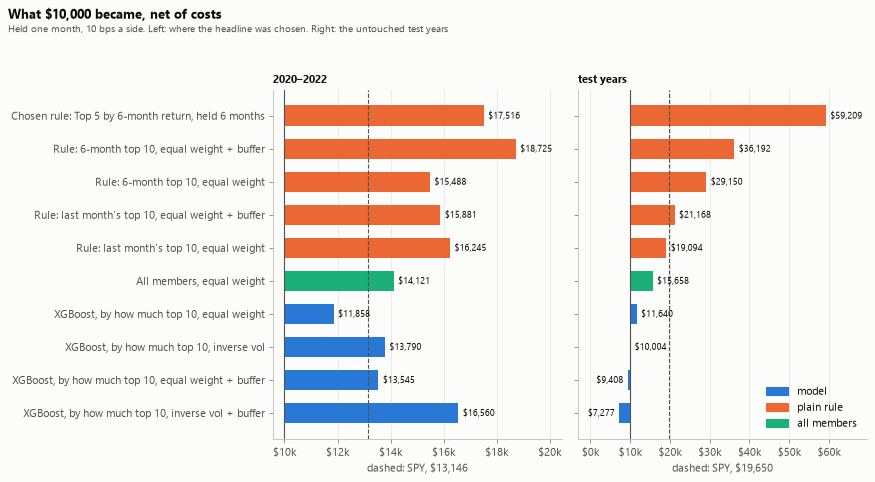

In [14]:
fig = plots.strategy_value_chart(
    tables,
    labels,
    kinds,
    "What $10,000 became, net of costs",
    "Held one month, 10 bps a side. Left: where the headline was chosen. Right: the untouched test years",
)
plots.save(fig, "strategies_value")

## 8. Every model, for reference

All eight candidates at top 10, equal weight, in both periods. Only the headline was chosen in advance;
the others are shown so the choice can be judged, never to pick from.

In [15]:
ref = [f"{m}_top10_equal" for m in models] + ["mom_6m_top10_equal", "mom_1m_top10_equal", "spy"]
cols = ["end_value", "cagr", "sharpe", "max_drawdown", "traded_per_year"]
both = pd.concat({p: t.loc[ref, cols] for p, t in tables.items()}, axis=1)
both.index = [plots.strategy_label(n, model_labels) for n in ref]
both.sort_values(("2020–2022", "sharpe"), ascending=False)

2020–2022                                              test years                                             
                                             end_value    cagr sharpe max_drawdown traded_per_year   end_value    cagr  sharpe max_drawdown traded_per_year
Rule: last month's top 10, equal weight    16,244.8149  0.1755 0.7287      -0.3128         23.3333 19,093.8781  0.1882  0.5697      -0.3044         22.5600
Rule: 6-month top 10, equal weight         15,488.0085  0.1570 0.6067      -0.2205         11.1040 29,149.7097  0.3302  0.8382      -0.2557         10.8304
Decision tree top 10, equal weight         13,991.9921  0.1185 0.5033      -0.1605         16.5099 18,253.6538  0.1741  0.8022      -0.0785         19.2116
SPY                                        13,145.6746  0.0955 0.4840      -0.2331             NaN 19,649.6435  0.1974  1.2059      -0.0780             NaN
XGBoost, ranking top 10, equal weight      11,979.5265  0.0621 0.3827      -0.4564         11.7635  6,926.1571 -0.0933 -0.3252      -0.3517         10.2201
XGBoost, by how much top 10, equal weight  11,857.6293  0.0584 0.3774      -0.4756         18.1744 11,639.9977  0.0413  0.1156      -0.3097         11.6992
Neural network (MLP) top 10, equal weight  10,747.8973  0.0243 0.2321      -0.3322         18.9425 23,087.0930  0.2500  1.0650      -0.0862         17.8952
Random forest top 10, equal weight          9,130.5225 -0.0299 0.2085      -0.5147         20.6811 16,959.5998  0.1513  0.7064      -0.0726         20.8871
Logistic regression top 10, equal weight    9,862.2656 -0.0046 0.2074      -0.3900         16.8851 19,016.5317  0.1870  0.6214      -0.3240         15.8834
Average of the models top 10, equal weight  9,290.6411 -0.0242 0.1881      -0.4043         20.5694 17,724.1747  0.1649  0.6379      -0.1709         21.5905
XGBoost, beat or not top 10, equal weight   7,579.2356 -0.0883 0.0135      -0.4737         19.7570 13,052.5459  0.0736  0.2344      -0.2548         21.5637

What the buffer and the weighting changed, on average over the eight models at top 10 (each
version minus the plain equal-weight version):

In [16]:
change = pd.concat({p: bt.version_effect(t, models, top_n=10) for p, t in tables.items()})
change.rename(index=plots.VERSION_LABELS)

cagr  sharpe  max_drawdown  traded_per_year
           version                                                             
2020–2022  equal weight + buffer  0.0101  0.0102        0.0075          -3.5579
           inverse vol            0.0348  0.0542        0.0147           1.2874
           inverse vol + buffer   0.0555  0.0847        0.0264          -1.4649
test years equal weight + buffer  0.0029  0.0272       -0.0032          -2.9018
           inverse vol           -0.0334 -0.1117       -0.0440           1.6325
           inverse vol + buffer  -0.0332 -0.0973       -0.0371          -0.7469

## 9. What Part 2 means

- **Traded, the headline model loses to SPY and to every plain rule.**
  - On the test years, $10,000 in its main version (equal weight) became $11,640, against $19,650 in
    SPY (Sharpe 0.12 vs 1.21).
  - On 2020–2022 it became $11,858, against SPY's $13,146.
  - Both 1-month rules at top 10 (with or without the buffer), and the rule chosen in Part 1, did
    better than the headline in both periods.
- **The version that looked best on 2020–2022 did worst on the test.** With inverse volatility and
  the buffer, the headline turned $10,000 into $16,560 on 2020–2022 (Sharpe 0.54, above SPY's 0.48),
  then into $7,277 on the test years. That's the reason only the main version was fixed as the
  headline: choosing the best of four versions on three years picks up luck.
- **The models trade a lot.** At top 10 they buy and sell about 18 times the portfolio a year, versus
  11 for the 6-month rule and 23 for last month's. For the headline that cost about $600 in fees on
  $10,000 over 2020–2022.
- **The buffer did what it's for.** Averaged over the eight models at top 10, it cut trading by about 3
  portfolio-turns a year in both periods, and changed the Sharpe ratio by little (+0.01 and +0.03). For
  the 6-month rule at top 10 it helped in both periods: Sharpe 0.61 → 0.85 on 2020–2022, 0.84 → 0.98 on
  the test. At top 1 and top 5 it didn't help consistently.
- **Inverse-volatility weighting didn't help consistently.** It raised the models' average Sharpe on
  2020–2022 (+0.05) and lowered it on the test (−0.11).
- **A few strategies edge SPY's Sharpe on the test.** 12 of the 121 strategies do. Among so many
  related tries, a few are expected to by chance. Most hold a single stock (top 1 of the tree, the MLP or the 6-month rule). Among the
  pre-declared ones, only the rule chosen in Part 1 does, and that's a tie (1.21 vs 1.21). The MLP
  was the best model on the test ($23,087 at top 10), after a weak 2020–2022 ($10,748). Picking it now
  would be choosing on the test.
- **What this means:** on this data, the models add nothing a plain 6-month momentum rule doesn't
  already do better. No strategy chosen in advance clearly beats SPY per unit of risk in the test
  years; the best is a tie.
  Equity curves, rolling returns and the SPY trend filter follow in the next step.
- All numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
